In [2]:
# Baseline model interpretation: per-model prediction plots and official-metric scores.
# Each trained/untrained baseline gets its own section: a prediction-vs-actual plot for
# one turbine in one window, then RMSE / MAE / competition score
import os, sys, glob, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- paths ---
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "windevolve_sdwpf"))
if not os.path.isdir(REPO):
    REPO = "/home/dorsa/srip/windevolve_sdwpf"
if REPO not in sys.path:
    sys.path.insert(0, REPO)
for sub in ["baseline_models/naive", "baseline_models/classical", "baseline_models/tree", "baseline_models/gru"]:
    p = os.path.join(REPO, sub)
    if p not in sys.path:
        sys.path.insert(0, p)

import metrics
from test_data import TestData
import evaluator as EV

TEST_DIR = EV.TEST_DIR
CAPACITY, HORIZON, DAY_LEN = 134, 288, 144

# which turbine / window to visualize (change freely)
SHOW_TURBINE = 0
SHOW_WINDOW = 0
N_WINDOWS = None          # None = all 142; set e.g. 20 for a fast pass while iterating

np.random.seed(1)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NAVY, GOLD, RUST, TEAL = "#3C3489", "#C8A227", "#D85A30", "#1D9E75"

infiles = sorted(glob.glob(os.path.join(TEST_DIR, "infile", "*in.csv")))
outfiles = sorted(glob.glob(os.path.join(TEST_DIR, "outfile", "*out.csv")))
print("test dir :", TEST_DIR)
print("windows  :", len(infiles), "| showing turbine", SHOW_TURBINE, "window", SHOW_WINDOW)

test dir : /home/dorsa/srip/wind_forecasting_data/sdwpf_kddcup/final_phase_test
windows  : 142 | showing turbine 0 window 0


In [3]:
# Shared helpers: run any baseline through the official metric, and pull one
# turbine/window prediction + masked ground truth for plotting.

def masked_truth(raw_df):
    """Return (truth_kW, keep_mask) applying the official masking rules to one turbine-window."""
    r = raw_df.reset_index(drop=True)
    invalid = (pd.isna(r).any(axis=1)
               | (r["Patv"] < 0)
               | ((r["Patv"] == 0) & (r["Wspd"] > 2.5))
               | (r["Pab1"] > 89) | (r["Pab2"] > 89) | (r["Pab3"] > 89)
               | (r["Wdir"] < -180) | (r["Wdir"] > 180)
               | (r["Ndir"] < -720) | (r["Ndir"] > 720)).to_numpy()
    return r["Patv"].to_numpy(dtype=float), ~invalid

def one_window_prediction(module, tid, widx):
    """Run a model's forecast on one window; return (pred_kW, truth_kW, keep_mask) for turbine tid."""
    envs = EV.prep_env()
    envs["path_to_test_x"] = infiles[widx]
    preds = module.forecast(envs)                    # (134, 288, 1) kW
    pred = np.asarray(preds)[tid, :, 0]
    td = TestData(path_to_data=outfiles[widx], start_col=3, farm_capacity=CAPACITY)
    seqs, raws = td.get_all_turbines()
    truth = np.asarray(seqs[tid][:HORIZON, -1], dtype=float)
    _, keep = masked_truth(raws[tid])
    return pred, truth, keep

def score_model(module_path, n_windows=N_WINDOWS):
    """Score a baseline through the official evaluator. Returns the result dict."""
    return EV.evaluate(module_path, test_dir=TEST_DIR, n_windows=n_windows)

def show_prediction(module, name, tid=SHOW_TURBINE, widx=SHOW_WINDOW):
    """Plot predicted vs actual for one turbine in one window, marking masked steps."""
    pred, truth, keep = one_window_prediction(module, tid, widx)
    hours = np.arange(1, HORIZON + 1) * 10 / 60.0
    plt.figure()
    plt.plot(hours, truth / 1000, color=NAVY, lw=1.6, label="actual")
    plt.plot(hours, pred / 1000, color=RUST, lw=1.6, label="predicted")
    masked = ~keep
    if masked.any():
        plt.scatter(hours[masked], truth[masked] / 1000, s=12, color="#A32D2D",
                    zorder=3, label="masked ({})".format(masked.sum()))
    plt.xlabel("hours ahead"); plt.ylabel("power (MW)")
    plt.title("{} — turbine {}, window {}".format(name, tid, widx + 1))
    plt.legend(); plt.tight_layout(); plt.show()

    # per-turbine-window score on the scored steps only
    e = (pred[keep] - truth[keep]) / 1000.0
    if len(e):
        rmse = float(np.sqrt((e ** 2).mean())); mae = float(np.abs(e).mean())
        print("this turbine/window: RMSE {:.4f}  MAE {:.4f}  score {:.4f} MW  ({} scored steps)".format(
            rmse, mae, 0.5 * (rmse + mae), keep.sum()))

def report_score(name, res):
    """Print the farm-level official score for a model."""
    if res.get("valid"):
        print("{:<22} RMSE {:.3f}  MAE {:.3f}  competition score {:.3f} MW  ({} windows, {:.0f}s)".format(
            name, res["rmse"], res["mae"], res["competition_score"], res["n_windows"], res.get("eval_seconds", 0)))
    else:
        print("{:<22} INVALID: {}".format(name, res.get("reason", "")[:60]))
    return res

RESULTS = {}          # name -> official result dict, collected for the summary
print("helpers ready")

helpers ready


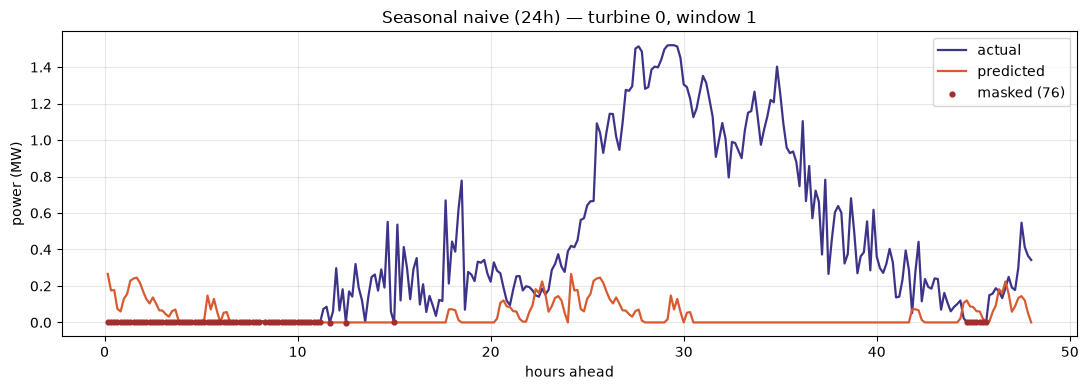

this turbine/window: RMSE 0.6977  MAE 0.5311  score 0.6144 MW  (212 scored steps)


In [4]:
# ================================================================
# 1. Seasonal naive (daily, LAG=144)  —  no training required
# ================================================================
os.environ["SDWPF_NAIVE_LAG"] = "144"
import baseline_naive; importlib.reload(baseline_naive)
show_prediction(baseline_naive, "Seasonal naive (24h)")

In [5]:
RESULTS["Seasonal naive (24h)"] = report_score(
    "Seasonal naive (24h)",
    score_model(os.path.join(REPO, "baseline_models/naive/baseline_naive.py")))
# Analysis: naive repeats the last day. It tracks the daily shape but cannot react to
# anything new, so error grows with horizon and spikes wherever the copied day differs
# from the true future.

Seasonal naive (24h)   RMSE 69.623  MAE 56.609  competition score 63.116 MW  (142 windows, 36s)


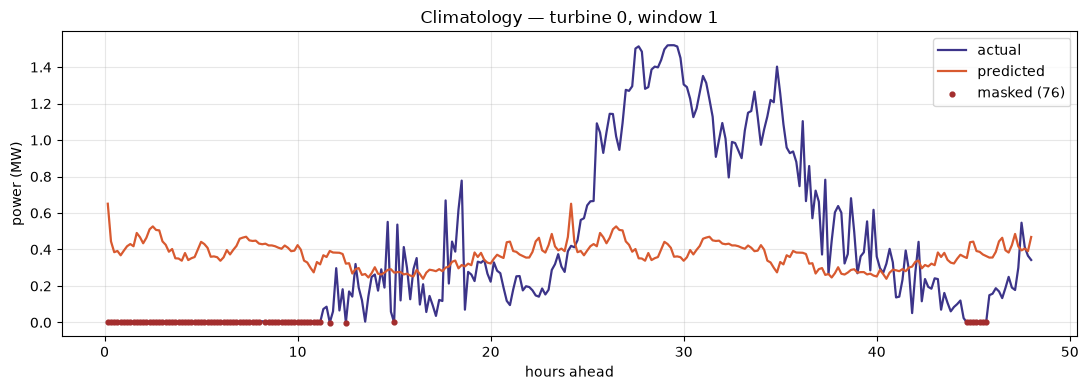

this turbine/window: RMSE 0.4794  MAE 0.3577  score 0.4185 MW  (212 scored steps)


In [6]:
# ================================================================
# 1b. Diurnal climatology  —  no training required
# ================================================================
# Average power by TIME OF DAY over the history, tiled across 48h. Uses no recent
# state, so it is the "what does this turbine usually do at this hour" reference.
import baseline_climatology; importlib.reload(baseline_climatology)
show_prediction(baseline_climatology, "Climatology")

In [7]:
RESULTS["Climatology"] = report_score(
    "Climatology",
    score_model(os.path.join(REPO, "baseline_models/classical/baseline_climatology.py")))
# Analysis: climatology ignores current conditions entirely — the forecast is the average
# daily shape regardless of what the turbine is doing right now. On this dataset recent
# power is the strongest predictor, so climatology typically trails the naive baseline.
# It is a valid tier-1 reference precisely because it isolates the diurnal component.

Climatology            RMSE 53.772  MAE 44.483  competition score 49.127 MW  (142 windows, 37s)


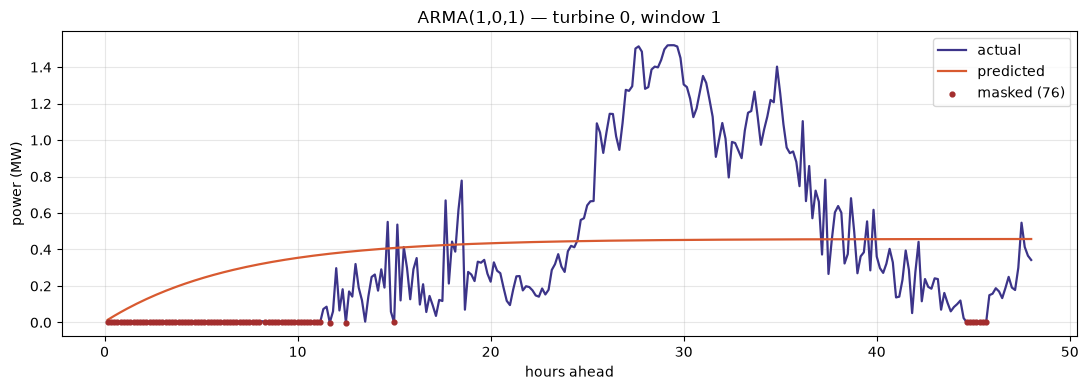

this turbine/window: RMSE 0.4597  MAE 0.3662  score 0.4130 MW  (212 scored steps)


In [8]:
# ================================================================
# 2. ARMA(1,0,1)  —  fitted on 245 days, order chosen by ADF (d=0)
# ================================================================
os.environ["SDWPF_ARIMA_MODEL"] = os.path.join(REPO, "baseline_models/classical/arma_101.joblib")
import baseline_arima; importlib.reload(baseline_arima)
baseline_arima._CACHE["fits"] = None        # clear cache so the chosen model file loads
show_prediction(baseline_arima, "ARMA(1,0,1)")

In [9]:
RESULTS["ARMA(1,0,1)"] = report_score(
    "ARMA(1,0,1)",
    score_model(os.path.join(REPO, "baseline_models/classical/baseline_arima.py")))
# Analysis: ARMA eases from the last value toward the series mean. Smooth and well-matched
# to the strong short-lag autocorrelation, which is why it is the best classical baseline.

ARMA(1,0,1)            RMSE 51.456  MAE 41.998  competition score 46.727 MW  (142 windows, 118s)


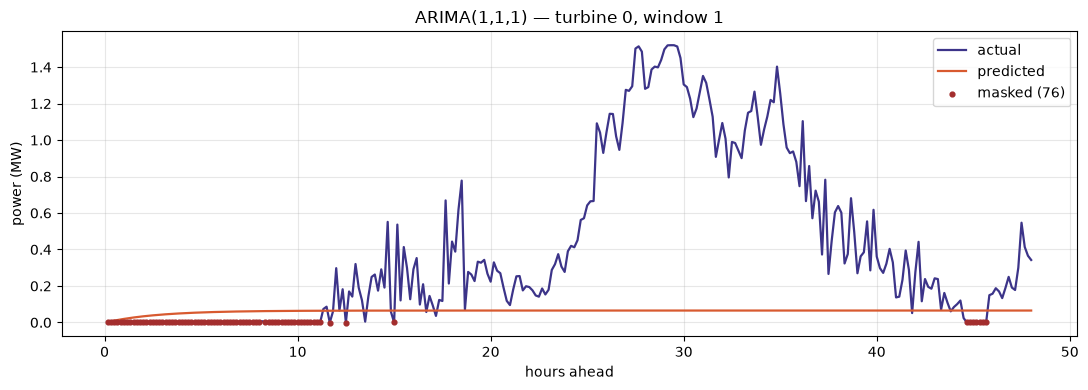

this turbine/window: RMSE 0.6728  MAE 0.5013  score 0.5871 MW  (212 scored steps)


In [10]:
# ================================================================
# 3. ARIMA(1,1,1)  —  the over-differenced variant, for contrast
# ================================================================
os.environ["SDWPF_ARIMA_MODEL"] = os.path.join(REPO, "baseline_models/classical/arima_111.joblib")
importlib.reload(baseline_arima)
baseline_arima._CACHE["fits"] = None
show_prediction(baseline_arima, "ARIMA(1,1,1)")

In [11]:
RESULTS["ARIMA(1,1,1)"] = report_score(
    "ARIMA(1,1,1)",
    score_model(os.path.join(REPO, "baseline_models/classical/baseline_arima.py")))
# Analysis: d=1 differences an already-stationary series (the ADF test rejects a unit root),
# so this is over-differenced. It scores worse than ARMA(1,0,1) — evidence that order
# selection matters, and that the ADF-chosen d=0 is correct.

ARIMA(1,1,1)           RMSE 57.613  MAE 47.199  competition score 52.406 MW  (142 windows, 118s)


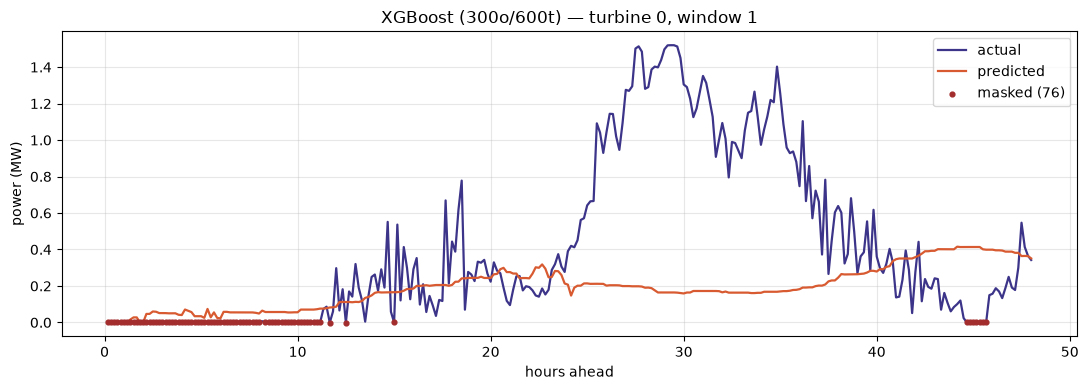

this turbine/window: RMSE 0.5947  MAE 0.4220  score 0.5084 MW  (212 scored steps)


In [12]:
# ================================================================
# 4. XGBoost GBDT  —  one global model, reads wind speed
# ================================================================
os.environ["SDWPF_GBDT_MODEL"] = os.path.join(REPO, "baseline_models/tree/gbdt_300o_600t.joblib")
import baseline_gbdt; importlib.reload(baseline_gbdt)
baseline_gbdt._CACHE["model"] = None
show_prediction(baseline_gbdt, "XGBoost (300o/600t)")

In [13]:
RESULTS["XGBoost"] = report_score(
    "XGBoost",
    score_model(os.path.join(REPO, "baseline_models/tree/baseline_gbdt.py")))
# Analysis: the only baseline that reads wind speed, but without FUTURE wind its power-curve
# advantage decays over 48h. Note the piecewise-constant (blocky) prediction — trees predict
# in steps, which adds RMSE error on a smooth quantity. Lands ~tied with ARMA.

XGBoost                RMSE 52.418  MAE 42.726  competition score 47.572 MW  (142 windows, 39s)


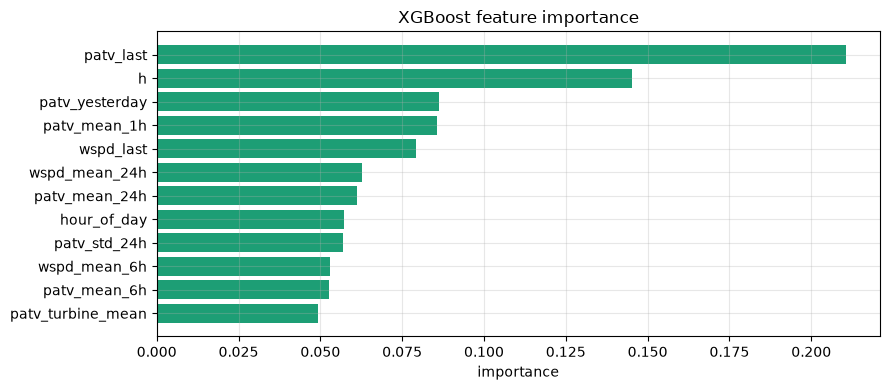

top features: patv_last (0.21), h (0.15), patv_yesterday (0.09), patv_mean_1h (0.09)


In [14]:
# XGBoost feature importances — which inputs the tree model actually uses.
blob = __import__("joblib").load(os.environ["SDWPF_GBDT_MODEL"])
model, feats = blob["model"], blob["features"]
imp = model.feature_importances_
order = np.argsort(imp)[::-1]
plt.figure(figsize=(9, 4))
plt.barh([feats[i] for i in order][::-1], imp[order][::-1], color=TEAL)
plt.xlabel("importance"); plt.title("XGBoost feature importance")
plt.tight_layout(); plt.show()
print("top features:", ", ".join("{} ({:.2f})".format(feats[i], imp[i]) for i in order[:4]))

looking in : /home/dorsa/srip/windevolve_sdwpf/baseline_models/gru/checkpoints
checkpoints found: 134 of 134


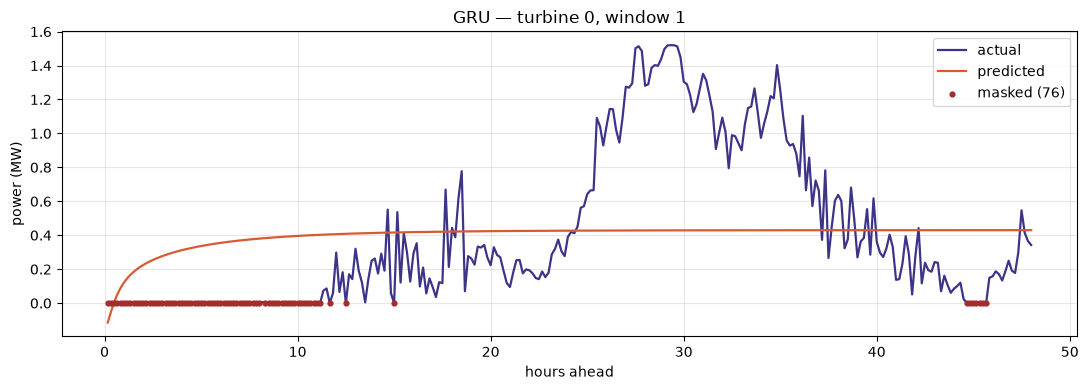

this turbine/window: RMSE 0.4696  MAE 0.3696  score 0.4196 MW  (212 scored steps)


SDWPF eval took 197.2s for 142 windows -- approaching OpenEvolve's 300s per-candidate timeout (a timeout collapses to fitness 0.0, which outranks valid negative scores). Consider speeding up the eval.


GRU                    RMSE 51.361  MAE 42.011  competition score 46.686 MW  (142 windows, 197s)


In [15]:
# ================================================================
# 5. GRU  —  134 per-turbine models
# ================================================================
# Scores all 134 if present. The GRU reads checkpoints from baseline_models/gru/checkpoints/
# via SDWPF_GRU_CHECKPOINTS or its own default (dirname of gru_baseline.py).

GRU_CKPT = os.environ.get("SDWPF_GRU_CHECKPOINTS",
                          os.path.join(REPO, "baseline_models/gru/checkpoints"))
have = sorted(int(os.path.basename(p).split("_")[1].split(".")[0])
              for p in glob.glob(os.path.join(GRU_CKPT, "model_*.pt")))
print("looking in :", GRU_CKPT)
print("checkpoints found:", len(have), "of", CAPACITY)

if len(have) >= CAPACITY:
    import gru_baseline; importlib.reload(gru_baseline)
    show_prediction(gru_baseline, "GRU")
    RESULTS["GRU"] = report_score(
        "GRU", score_model(os.path.join(REPO, "baseline_models/gru/gru_baseline.py")))
elif have:
    print("Only {} of {} turbines — showing turbine {} in isolation "
          "(pipeline check, NOT comparable).".format(len(have), CAPACITY, have[0]))
    import gru_baseline; importlib.reload(gru_baseline)
    try:
        show_prediction(gru_baseline, "GRU (partial)", tid=have[0])
    except Exception as e:
        print("could not plot:", str(e)[:80])
else:
    print("No checkpoints at that path. If they are elsewhere, set SDWPF_GRU_CHECKPOINTS")
    print("or check the path printed above matches where training wrote model_*.pt.")

BASELINE COMPARISON  (MW, summed over 134 turbines, averaged over windows; lower better)
               model  MAE_MW  RMSE_MW  score_MW  eval_s
                 GRU   42.01    51.36     46.69   197.2
         ARMA(1,0,1)   42.00    51.46     46.73   118.2
             XGBoost   42.73    52.42     47.57    39.4
         Climatology   44.48    53.77     49.13    36.6
        ARIMA(1,1,1)   47.20    57.61     52.41   118.0
Seasonal naive (24h)   56.61    69.62     63.12    36.2


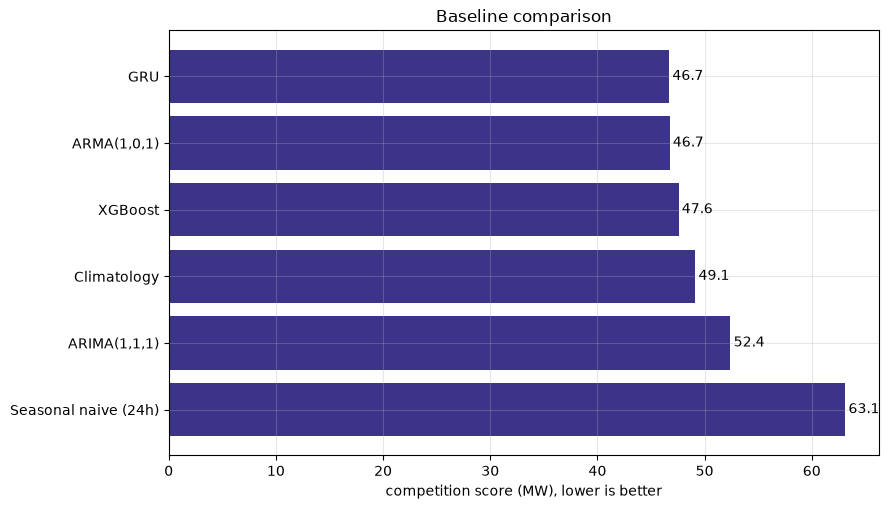

In [16]:
# ================================================================
# Summary — all scored baselines on the same windows and metric
# ================================================================
rows = []
for name, res in RESULTS.items():
    if res.get("valid"):
        rows.append({"model": name, "MAE_MW": round(res["mae"], 2),
                     "RMSE_MW": round(res["rmse"], 2),
                     "score_MW": round(res["competition_score"], 2),
                     "eval_s": round(res.get("eval_seconds", 0), 1)})
tbl = pd.DataFrame(rows).sort_values("score_MW").reset_index(drop=True)
print("BASELINE COMPARISON  (MW, summed over 134 turbines, averaged over windows; lower better)")
print(tbl.to_string(index=False))

if len(tbl):
    fig, ax = plt.subplots(figsize=(9, 0.7 * len(tbl) + 1))
    y = np.arange(len(tbl))
    ax.barh(y, tbl["score_MW"], color=NAVY)
    ax.set_yticks(y); ax.set_yticklabels(tbl["model"])
    ax.invert_yaxis(); ax.set_xlabel("competition score (MW), lower is better")
    for i, v in enumerate(tbl["score_MW"]):
        ax.text(v + 0.3, i, "{:.1f}".format(v), va="center")
    ax.set_title("Baseline comparison")
    plt.tight_layout(); plt.show()